### Goals:
- Predict a continuous output (y) from input features (x)

In [1]:
# Firstly import lib
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

import sys, os

sys.path.insert(0, os.path.abspath(''))

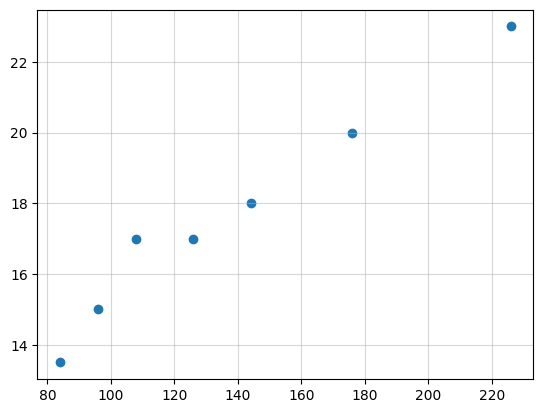

In [2]:
# assume an available sample of dots, which peforms price and area of houses
x = np.array([84, 96, 108, 126, 144, 176, 226])
y = np.array([13.5, 15, 17, 17, 18, 20, 23])

plt.scatter(x, y)
plt.grid(True, linestyle='-', alpha=0.5)
plt.show()

## A. Linear Regression

### The primary function, high applicability and connectivity with esential components of Regression and ML
- Assuming that the output value y is a linear combination of the features
$$
\hat{y} = w_0 + w_1x_1 + w_2x_2 + \dots + w_nx_n = \mathbf{w}^T \mathbf{x} + b
$$
- At that point, the model will learn the weights by minimising MSE
$$
\text{MSE} = \frac{1}{N} \sum (y_i - \hat{y}_i)^2
$$
- In case $X^T X$ is an invertible matrix, with small elements (n), the normal eqn is direct and effective:
$$
w^* = (X^T X)^{-1} X^T y
$$

In [8]:
# Observating that we have 7 elements
print(len(x), len(x) == len(y))

# Step 1: Create matrix of X
X = np.column_stack((np.ones(len(x)), x))
print(X)

# Step 2: Applicating the normal eqn 
w = np.linalg.inv(X.T @ X) @ X.T @ y

print(f"w0 (Intercept): {w[0]:.3f}")
print(f"w1 (Slope):     {w[1]:.3f}")

y_pred = X @ w
print("\nGiá trị dự đoán:", np.round(y_pred, 2))

# Evaluate use rmse
from src.regression import compute_mse

mse = compute_mse(y, y_pred=y_pred)
print("MSE:", mse)


7 True
[[  1.  84.]
 [  1.  96.]
 [  1. 108.]
 [  1. 126.]
 [  1. 144.]
 [  1. 176.]
 [  1. 226.]]
w0 (Intercept): 9.155
w1 (Slope):     0.062

Giá trị dự đoán: [14.35 15.1  15.84 16.95 18.07 20.05 23.14]
MSE: 0.3021469543840477


## Using Linear Regression to fit the sample data

We fit a line $\hat{y} = w x + b$ to the house-price data by minimizing the Mean Squared Error (MSE):

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

In [11]:
# Fit the model with scikit-learn
# sklearn expects 2D input for X: shape (n_samples, n_features)
X = np.array(x).reshape(-1, 1)
# print(X)
y_arr = np.array(y)

model = LinearRegression()
model.fit(X, y_arr)

w = model.coef_[0]
b = model.intercept_
print(f'Model: price = {w:.4f} * area + {b:.4f}')

Model: price = 0.0619 * area + 9.1547


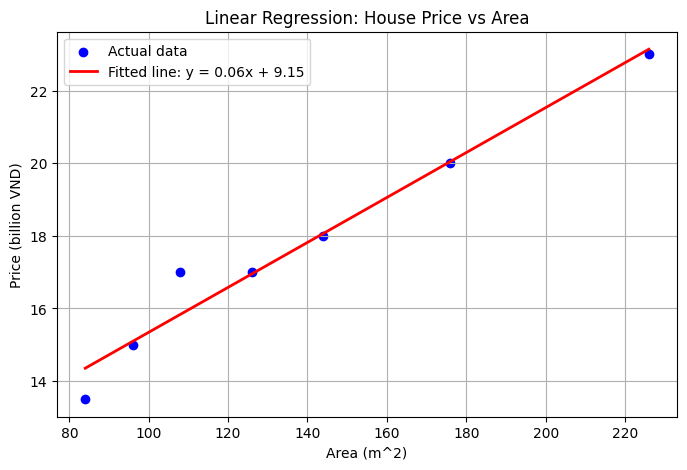

In [5]:
# Visualisation: data points, fitted line and predictions
y_pred = model.predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', label='Actual data')
plt.plot(x, y_pred, color='red', linewidth=2, label=f'Fitted line: y = {w:.2f}x + {b:.2f}')

plt.xlabel('Area (m^2)')
plt.ylabel('Price (billion VND)')
plt.title('Linear Regression: House Price vs Area')
plt.legend()
plt.grid(True)
plt.show()

MSE is optimal for use as a loss function and for model optimisation because it:
- Has a smooth derivative.
- Is computationally efficient.
- Magnifies large errors.

However, since the errors are squared, the units of measurement are also squared. To address this, RMSE (Root Mean Squared Error) is used to measure the average magnitude of the error between the model's predicted values ​​and the actual values.
$$
RMSE = \sqrt{MSE}
$$

To assess how well a model explains the overall picture, a metric called R-squared is used additionally, which is calculated according to the following formula:
$$
R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = \frac{SS_{exp}}{SS_{tot}}
$$
While
$$
SS_{res} = \sum_{i=1}^{N} (y_i - \hat{y}_i)^2,SS_{tot} = \sum_{i=1}^{N} (y_i - \bar{y})^2,SS_{exp} = \sum_{i=1}^2
$$
For instant, when $R^2 = 95\%$, it means model can explain $95\%$ fluctuation in housing prices

In [6]:
sk_mse = mean_squared_error(y, y_pred)
print(sk_mse, mse)

sk_r2 = r2_score(y, y_pred)
print(sk_r2)

0.30214695438404776 0.3021469543840477
0.9643677478584396


In real case, Data dimension intended for use is typically stripped of components that are unnecessary or have little impact on the overall dataset. The more redundant dimension of data is removed, the more computational performance is improved.

## B. Gradient Descent

### Iteratively update the weights (w) along the surface of the loss function:
$$
w \leftarrow w - \eta \cdot \nabla_w L(w)
$$

With $\nabla$ as learning rate

In [12]:
# Reuse available material
# print(x, y)
X = np.column_stack((np.ones(len(x)), x))
# print(X)

